# Loan Default Risk & Pricing — LendingClub 2007–2018

| Part | Sections | Owner | Viva focus |
|---|---|---|---|
| **A** | 1–8 | Student 1 | Data, leakage policy, EDA, features, baselines |
| **B** | 9–12 | Student 2 | Bias–variance, Random Forest, XGBoost tuning, feature selection |
| **C** | 13–17 | Student 3 | Model comparison, calibration, evaluation, pricing, deployment |

In [1]:
import os, gc, json, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, validation_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_recall_curve, RocCurveDisplay, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_ITER  = int(os.environ.get('LC_NITER', 18))
N_BOOT  = int(os.environ.get('LC_NBOOT', 500))
plt.rcParams['figure.dpi'] = 110

## 1. Problem

A lender commits money before knowing whether it comes back. We predict the **probability of default** using only what is known at application time.

Two errors, unequal costs: **approving a defaulter** loses most of the principal; **rejecting a good borrower** loses only the profit on that loan. We assume the first mistake costs **5×** more — that asymmetry drives every downstream decision on threshold and pricing.

Live app: **http://eab-credit.preview.james-benjamin.com/**

## 2. Data & Leakage Policy

| Group | Examples | Role |
|---|---|---|
| Application-time | loan amount, income, DTI, FICO, credit bureau counts | **Model inputs** |
| LC's own pricing | `int_rate`, `grade`, `sub_grade` | **Benchmark only** — never a model input |
| Outcome | `loan_status` | Builds the target |
| Post-origination | payments received, recoveries | **LGD measurement only** |

Using LC's pricing as a model input would be circular: we would be predicting risk from risk.

In [2]:
import kagglehub
DATA_DIR = kagglehub.dataset_download('wordsforthewise/lending-club')
DATA_FILES = [p for p in pathlib.Path(DATA_DIR).rglob('accepted_2007_to_2018Q4.csv*') if p.is_file()]
if not DATA_FILES:
    raise FileNotFoundError(f'No accepted-loans CSV file found under {DATA_DIR}')
DATA_PATH = str(DATA_FILES[0])

ALL_COLS = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

NUMERIC_CANDS = [
    'loan_amnt','annual_inc','dti','delinq_2yrs','inq_last_6mths','open_acc','pub_rec',
    'revol_bal','revol_util','total_acc','collections_12_mths_ex_med','acc_now_delinq',
    'tot_coll_amt','tot_cur_bal','total_rev_hi_lim','acc_open_past_24mths','avg_cur_bal',
    'bc_open_to_buy','bc_util','chargeoff_within_12_mths','delinq_amnt',
    'mo_sin_old_rev_tl_op','mo_sin_rcnt_rev_tl_op','mo_sin_rcnt_tl','mort_acc',
    'mths_since_recent_inq','num_accts_ever_120_pd','num_actv_bc_tl','num_actv_rev_tl',
    'num_bc_sats','num_bc_tl','num_il_tl','num_op_rev_tl','num_rev_accts',
    'num_rev_tl_bal_gt_0','num_sats','num_tl_120dpd_2m','num_tl_30dpd',
    'num_tl_90g_dpd_24m','pct_tl_nvr_dlq','percent_bc_gt_75','pub_rec_bankruptcies',
    'tax_liens','tot_hi_cred_lim','total_bal_ex_mort','total_bc_limit',
    'total_il_high_credit_limit','fico_range_low','fico_range_high',
]
CAT_CANDS   = ['term','emp_length','home_ownership','verification_status','purpose','application_type']
DATE_COLS   = ['issue_d','earliest_cr_line']
BENCHMARK   = ['int_rate','grade','sub_grade']
OUTCOME     = ['funded_amnt','total_rec_prncp','recoveries']

keep = lambda cols: [c for c in cols if c in ALL_COLS]
USECOLS = sorted(set(
    keep(NUMERIC_CANDS) + keep(CAT_CANDS) + keep(DATE_COLS)
    + ['loan_status'] + keep(BENCHMARK) + keep(OUTCOME)
))

parts = []
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=USECOLS, chunksize=200_000, low_memory=False)):
    chunk = chunk[chunk['loan_status'].isin(['Fully Paid','Charged Off'])]
    if len(chunk):
        parts.append(chunk.sample(frac=0.08, random_state=RANDOM_STATE + i))
df = pd.concat(parts, ignore_index=True)
if len(df) > 150_000:
    df = df.sample(150_000, random_state=RANDOM_STATE)
del parts; gc.collect()

print(f'Sample: {df.shape[0]:,} rows, {df.shape[1]} columns')
print(f'Default rate: {(df["loan_status"]=="Charged Off").mean():.1%}')

Sample: 107,625 rows, 64 columns
Default rate: 20.0%


## 3. Cleaning & Target

Rules use fixed business limits, not data percentiles — no information leaks from test into train.

In [3]:
DF = df.copy()
DF['default'] = (DF['loan_status'] == 'Charged Off').astype(int)

# Type fixes
for c in keep(DATE_COLS):
    DF[c] = pd.to_datetime(DF[c], format='%b-%Y', errors='coerce')
if 'revol_util' in DF and DF['revol_util'].dtype == object:
    DF['revol_util'] = pd.to_numeric(DF['revol_util'].str.rstrip('%'), errors='coerce')
DF['term'] = DF['term'].astype(str).str.strip()
DF['fico_avg'] = DF[['fico_range_low','fico_range_high']].mean(axis=1)

# Business caps
before = len(DF)
DF = DF[DF['annual_inc'] > 0].copy()
DF['dti']       = DF['dti'].clip(0, 100)
DF['revol_util'] = DF['revol_util'].clip(0, 150)
DF['annual_inc'] = DF['annual_inc'].clip(upper=1_000_000)
DF = DF.replace([np.inf, -np.inf], np.nan).dropna(subset=['issue_d'])
DF = DF.sort_values('issue_d').reset_index(drop=True)

print(f'Removed {before - len(DF):,} rows | {len(DF):,} remain | default rate {DF["default"].mean():.1%}')

Removed 31 rows | 107,594 remain | default rate 20.0%


## 4. Exploratory Data Analysis

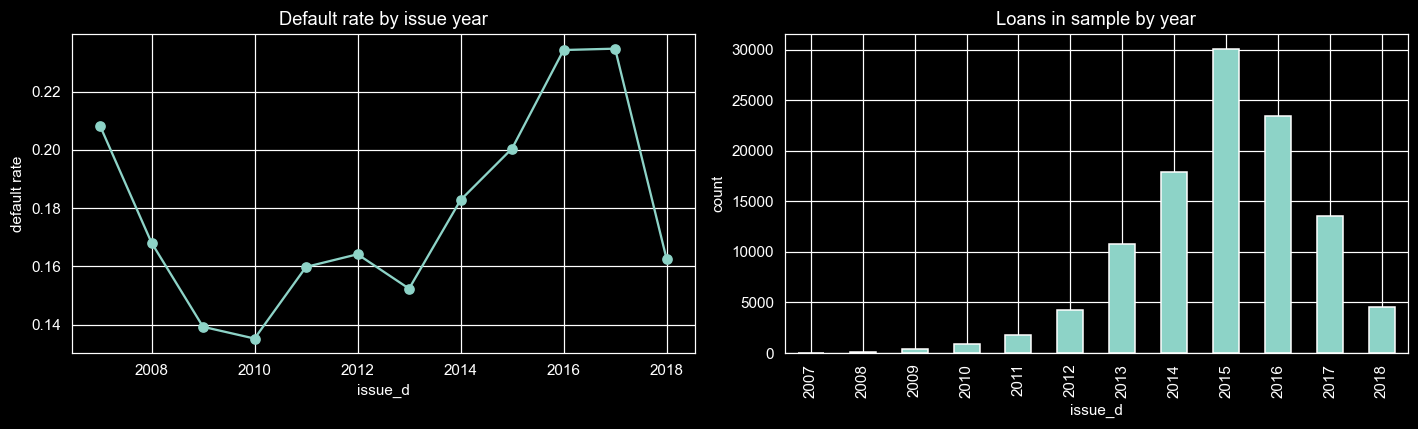

In [4]:
year = DF['issue_d'].dt.year
by_year = DF.groupby(year)['default'].agg(loans='size', default_rate='mean')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_year['default_rate'].plot(marker='o', ax=axes[0], title='Default rate by issue year', ylabel='default rate')
by_year['loans'].plot(kind='bar', ax=axes[1], title='Loans in sample by year', ylabel='count')
plt.tight_layout(); plt.show()

**Finding:** Default rate shifts with time — a random train/test split would mix future signal into training. We use a time-based split.

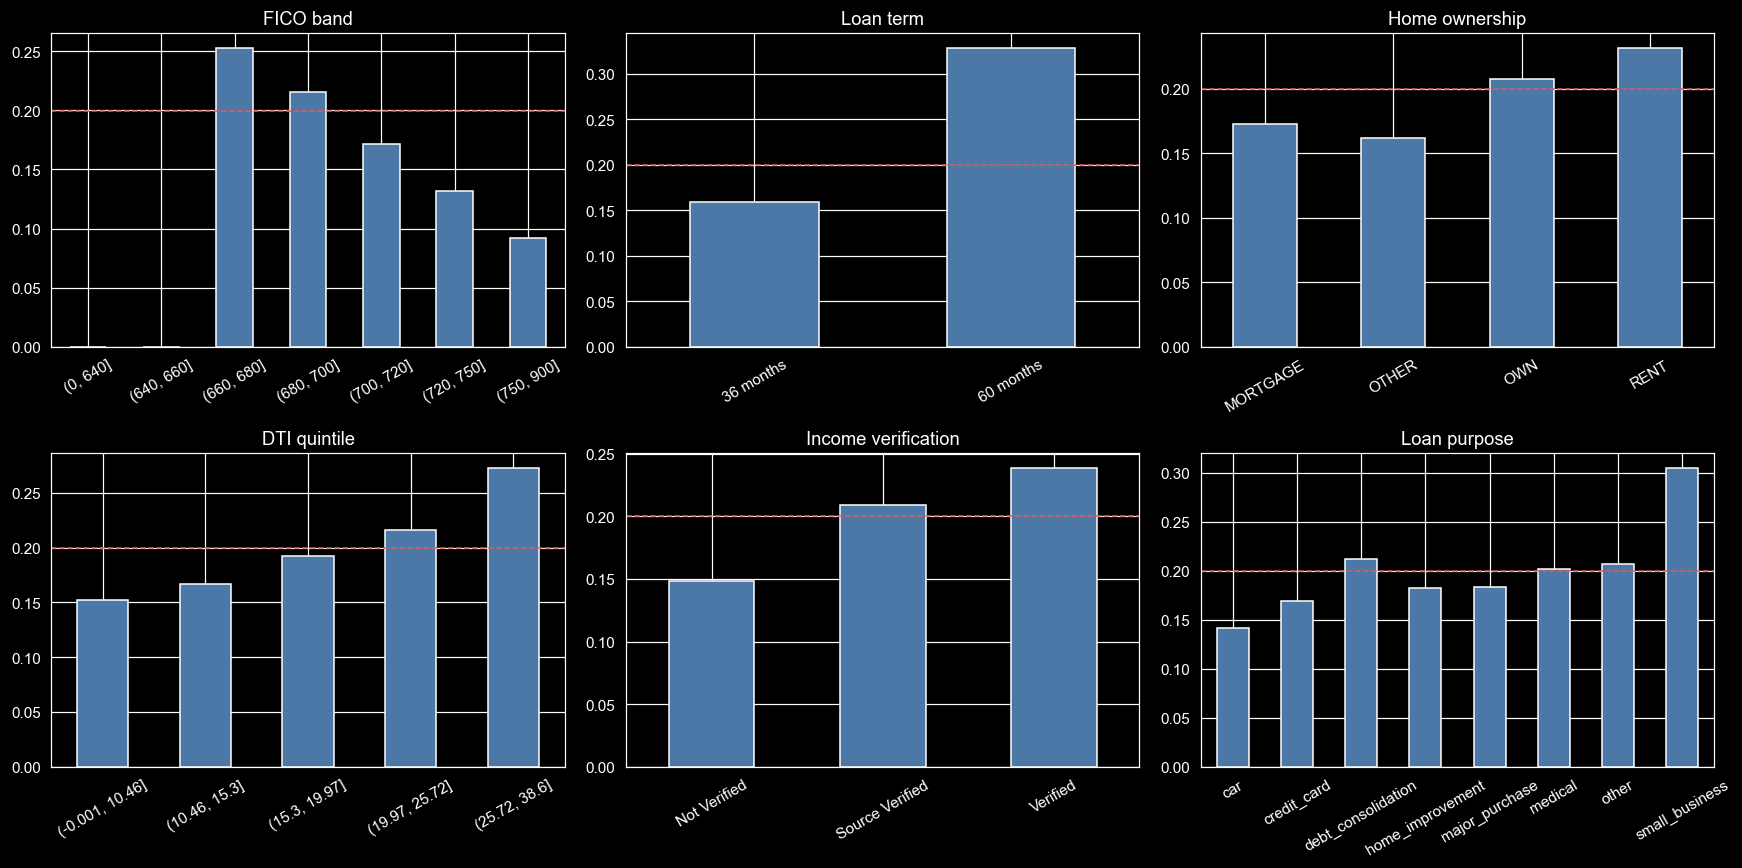

In [5]:
def rate_bar(series, ax, title):
    rate = DF.groupby(series, observed=False)['default'].mean()
    rate.plot(kind='bar', ax=ax, color='#4C78A8')
    ax.axhline(DF['default'].mean(), color='#E45756', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
rate_bar(pd.cut(DF['fico_avg'], [0,640,660,680,700,720,750,900]), ax[0,0], 'FICO band')
rate_bar(DF['term'], ax[0,1], 'Loan term')
rate_bar(DF['home_ownership'].where(DF['home_ownership'].isin(['MORTGAGE','RENT','OWN']),'OTHER'), ax[0,2], 'Home ownership')
dti_c = DF['dti'].clip(upper=DF['dti'].quantile(0.99))
rate_bar(pd.qcut(dti_c, 5, duplicates='drop'), ax[1,0], 'DTI quintile')
rate_bar(DF['verification_status'], ax[1,1], 'Income verification')
top_p = DF['purpose'].value_counts().head(8).index
rate_bar(DF['purpose'].where(DF['purpose'].isin(top_p), 'other'), ax[1,2], 'Loan purpose')
plt.tight_layout(); plt.show()

**Findings:** Higher FICO → lower default (strongest raw signal). 60-month loans default at roughly twice the rate of 36-month. Verified income often shows *higher* default — lenders verify applicants they already find suspicious.

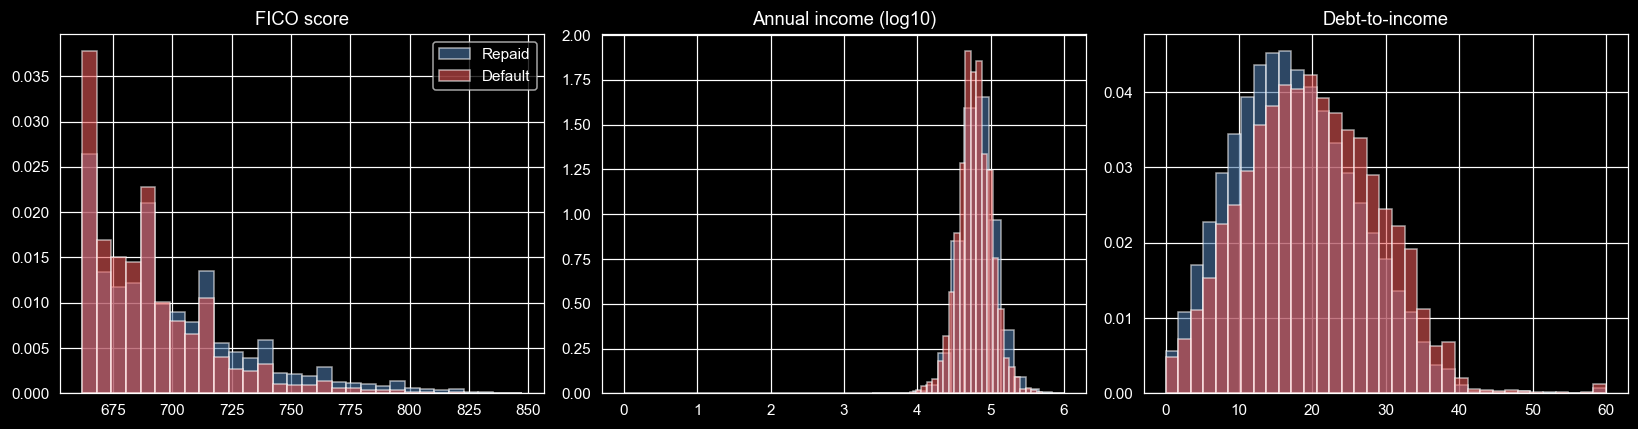

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for label, colour, name in [(0,'#4C78A8','Repaid'), (1,'#E45756','Default')]:
    d = DF[DF['default'] == label]
    ax[0].hist(d['fico_avg'],            bins=30, alpha=0.6, density=True, color=colour, label=name)
    ax[1].hist(np.log10(d['annual_inc']),bins=35, alpha=0.6, density=True, color=colour, label=name)
    ax[2].hist(d['dti'].clip(0,60),      bins=35, alpha=0.6, density=True, color=colour, label=name)
ax[0].set_title('FICO score'); ax[1].set_title('Annual income (log10)'); ax[2].set_title('Debt-to-income')
ax[0].legend(); plt.tight_layout(); plt.show()

**Finding:** Defaulters skew lower FICO and higher DTI, but the distributions overlap heavily — no single variable cleanly separates the classes.

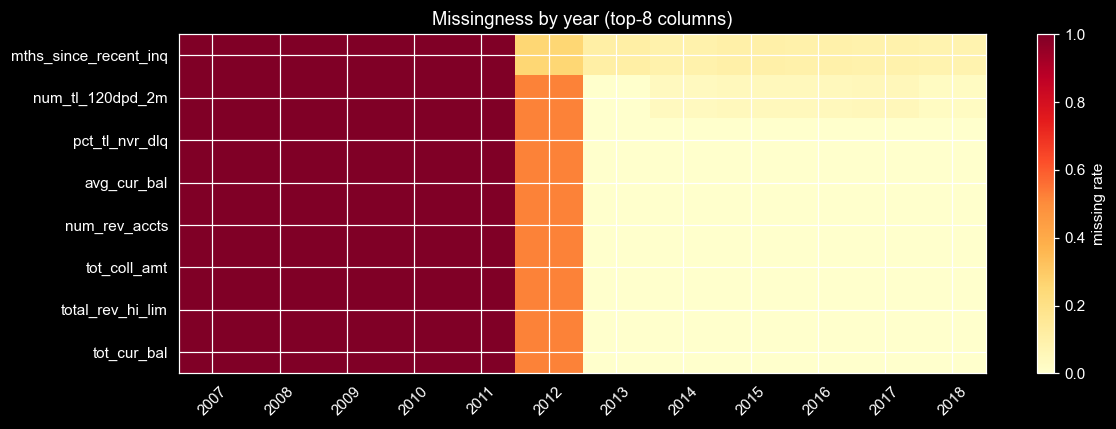

In [7]:
miss_by_year = DF.groupby(year)[keep(NUMERIC_CANDS)].apply(lambda g: g.isna().mean())
top_miss = miss_by_year.mean().sort_values(ascending=False).head(8).index.tolist()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(miss_by_year[top_miss].T, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(miss_by_year))); ax.set_xticklabels(miss_by_year.index, rotation=45)
ax.set_yticks(range(len(top_miss))); ax.set_yticklabels(top_miss)
plt.colorbar(im, ax=ax, label='missing rate'); ax.set_title('Missingness by year (top-8 columns)')
plt.tight_layout(); plt.show()

**Finding:** Several credit-bureau columns were not collected before 2012–2013. Missingness is systematic, not random — we add missing indicators so the model can use this information.

## 5. Feature Engineering

Two ratio features motivated by the EDA. Each must show a monotone relationship with default to earn its place.

In [8]:
DF['loan_to_income']       = DF['loan_amnt'] / DF['annual_inc'].replace(0, np.nan)
DF['credit_history_years'] = ((DF['issue_d'] - DF['earliest_cr_line']).dt.days / 365.25).clip(lower=0)
# fico_avg already created in section 3

for feat in ['loan_to_income','credit_history_years','fico_avg']:
    s = DF[feat].clip(upper=DF[feat].quantile(0.99))
    dr = DF.groupby(pd.qcut(s, 5, duplicates='drop'), observed=False)['default'].mean().round(3)
    print(f'{feat}:\n  {dr.values}  (monotone = justified)\n')

NUMERIC_FEATS = (
    [c for c in keep(NUMERIC_CANDS) if c not in ('fico_range_low','fico_range_high')]
    + ['fico_avg','loan_to_income','credit_history_years']
)
CAT_FEATS   = keep(CAT_CANDS)
FEAT_COLS   = NUMERIC_FEATS + CAT_FEATS

# Leakage guard
forbidden = set(BENCHMARK + OUTCOME + ['loan_status','default','issue_d','earliest_cr_line'])
assert not (set(FEAT_COLS) & forbidden), set(FEAT_COLS) & forbidden
print(f'Feature set: {len(NUMERIC_FEATS)} numeric + {len(CAT_FEATS)} categorical = {len(FEAT_COLS)} total')

loan_to_income:
  [0.134 0.159 0.186 0.231 0.291]  (monotone = justified)

credit_history_years:
  [0.223 0.213 0.195 0.193 0.175]  (monotone = justified)

fico_avg:
  [0.256 0.236 0.21  0.168 0.11 ]  (monotone = justified)

Feature set: 50 numeric + 6 categorical = 56 total


### Save the preprocessed dataset
The cleaned sample with the engineered features is saved to `data/loans_clean.csv.gz` (compressed so it stays well below GitHub's file-size limit). Anyone can reproduce the modelling steps from this file without downloading the full 2.2-million-loan dataset.

In [9]:
os.makedirs('data', exist_ok=True)
DF.to_csv('data/loans_clean.csv.gz', index=False, compression='gzip')
size_mb = os.path.getsize('data/loans_clean.csv.gz') / 1e6
print(f'Saved data/loans_clean.csv.gz: {len(DF):,} rows x {DF.shape[1]} columns ({size_mb:.1f} MB)')

Saved data/loans_clean.csv.gz: 107,594 rows x 68 columns (10.3 MB)


## 6. Time-Based Split

Sorted by issue date: oldest 70% train, next 15% validation, newest 15% test. The base rate shifts across periods (see EDA) — a random split would leak future patterns into training.

In [10]:
n = len(DF); i1, i2 = int(n * 0.70), int(n * 0.85)
train_df = DF.iloc[:i1].copy()
val_df   = DF.iloc[i1:i2].copy()
test_df  = DF.iloc[i2:].copy()

y_train, y_val, y_test = train_df['default'], val_df['default'], test_df['default']

for nm, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{nm:5s}  n={len(d):>7,}  {d['issue_d'].min():%Y-%m} → {d['issue_d'].max():%Y-%m}  default {d['default'].mean():.1%}")

train  n= 75,315  2007-07 → 2016-04  default 18.6%
val    n= 16,139  2016-04 → 2017-02  default 25.0%
test   n= 16,140  2017-02 → 2018-12  default 21.4%


## 7. Preprocessing & Metric Helpers

All preprocessing (imputation, scaling, encoding) is fitted on training data only and applied identically to validation and test.

In [11]:
def make_preprocess(num, cat):
    steps = []
    if num:
        steps.append(('num', Pipeline([
            ('imp', SimpleImputer(strategy='median', add_indicator=True)),
            ('sc',  StandardScaler())
        ]), num))
    if cat:
        steps.append(('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('oh',  OneHotEncoder(handle_unknown='ignore', min_frequency=20))
        ]), cat))
    return ColumnTransformer(steps)

def make_pipe(estimator, num, cat):
    return Pipeline([('prep', make_preprocess(num, cat)), ('model', estimator)])

# ── Metric helpers ──────────────────────────────────────────────────────────
def top_decile_lift(y, p, frac=0.10):
    y, p = np.asarray(y), np.asarray(p)
    k = max(int(len(y) * frac), 1)
    return float(y[np.argsort(-p)[:k]].mean() / y.mean())

def ece(y, p, bins=10):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    d['bin'] = pd.qcut(d['p'], bins, duplicates='drop')
    g = d.groupby('bin', observed=False).agg(mp=('p','mean'), obs=('y','mean'), n=('y','size'))
    return float((g['n'] * (g['mp'] - g['obs']).abs()).sum() / g['n'].sum())

def score_row(name, y, p):
    return {'Model': name,
            'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC':  average_precision_score(y, p),
            'Brier':   brier_score_loss(y, p),
            'ECE':     ece(y, p),
            'Lift@10%': top_decile_lift(y, p)}

def score_table(probs, y):
    return pd.DataFrame([score_row(k, y, v) for k, v in probs.items()]).set_index('Model').round(4)

# Storage
VAL, TEST, FITTED = {}, {}, {}

def fit_store(name, pipe, num, cat):
    cols = num + cat
    pipe.fit(train_df[cols], y_train)
    VAL[name]    = pipe.predict_proba(val_df[cols])[:, 1]
    TEST[name]   = pipe.predict_proba(test_df[cols])[:, 1]
    FITTED[name] = (pipe, cols)
    return pipe

print('Helpers ready.')

Helpers ready.


## 8. Baseline Models

Three references that set the performance bar before we build anything complex.

In [12]:
# 1. LC's own pricing — the incumbent risk assessment
lc_num, lc_cat = ['int_rate'], ['sub_grade']
fit_store('LC pricing',   make_pipe(LogisticRegression(max_iter=3000), lc_num, lc_cat),   lc_num, lc_cat)

# 2. FICO only — strongest single raw signal
fit_store('FICO only',    make_pipe(LogisticRegression(max_iter=3000), ['fico_avg'], []),  ['fico_avg'], [])

# 3. Logistic Regression on all 56 application features — transparent linear baseline
fit_store('Logistic',     make_pipe(LogisticRegression(max_iter=3000), NUMERIC_FEATS, CAT_FEATS), NUMERIC_FEATS, CAT_FEATS)

print('Validation scores:')
display(score_table({k: VAL[k] for k in ['LC pricing','FICO only','Logistic']}, y_val))
print('Any model we build must beat Logistic. LC pricing sets the business bar.')

Validation scores:


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%
Model,,,,,
LC pricing,0.6758,0.3912,0.1789,0.0642,1.8926
FICO only,0.5946,0.3040,0.1878,0.0643,1.3402
Logistic,0.6944,0.4207,0.1758,0.0656,2.0759


Any model we build must beat Logistic. LC pricing sets the business bar.


## 9. Bias–Variance: Random Forest depth

A shallow forest can underfit (high bias); a very deep forest can fit training noise (high variance). We compare train and validation ROC-AUC/PR-AUC across depths on a chronological training slice. The newest 15% remains untouched for final evaluation.

,train ROC-AUC,validation ROC-AUC,train PR-AUC,validation PR-AUC
max_depth,,,,
4,0.7264,0.6762,0.4103,0.4019
8,0.7775,0.6831,0.4821,0.4108
16,0.8894,0.6856,0.6596,0.4128


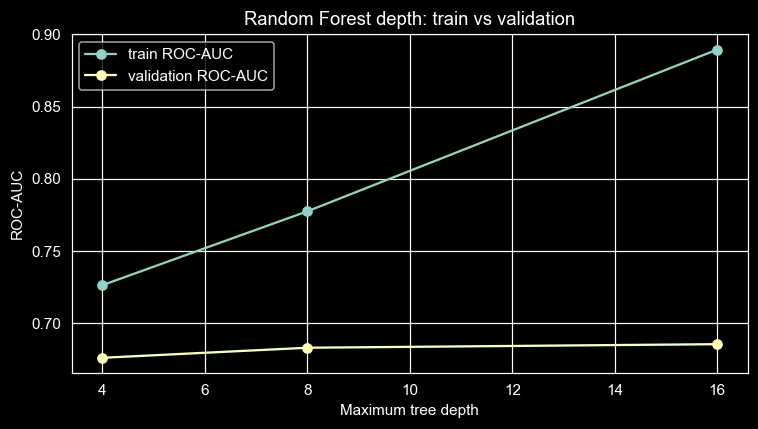

In [13]:
rf_diag_train = train_df.iloc[-min(40_000, len(train_df)):]
rf_diag_val = val_df.iloc[:min(15_000, len(val_df))]
rf_depths = [4, 8, 16]
rf_depth_rows = []

for depth in rf_depths:
    diagnostic_rf = make_pipe(
        RandomForestClassifier(
            n_estimators=80, max_depth=depth, min_samples_leaf=20,
            max_features='sqrt', class_weight='balanced_subsample',
            n_jobs=-1, random_state=RANDOM_STATE
        ), NUMERIC_FEATS, CAT_FEATS
    )
    diagnostic_rf.fit(rf_diag_train[FEAT_COLS], rf_diag_train['default'])
    train_prob = diagnostic_rf.predict_proba(rf_diag_train[FEAT_COLS])[:, 1]
    val_prob = diagnostic_rf.predict_proba(rf_diag_val[FEAT_COLS])[:, 1]
    rf_depth_rows.append({
        'max_depth': depth,
        'train ROC-AUC': roc_auc_score(rf_diag_train['default'], train_prob),
        'validation ROC-AUC': roc_auc_score(rf_diag_val['default'], val_prob),
        'train PR-AUC': average_precision_score(rf_diag_train['default'], train_prob),
        'validation PR-AUC': average_precision_score(rf_diag_val['default'], val_prob)
    })

rf_depth_results = pd.DataFrame(rf_depth_rows).set_index('max_depth')
display(rf_depth_results.round(4))
ax = rf_depth_results[['train ROC-AUC', 'validation ROC-AUC']].plot(
    marker='o', figsize=(7, 4), title='Random Forest depth: train vs validation'
)
ax.set_xlabel('Maximum tree depth'); ax.set_ylabel('ROC-AUC')
plt.tight_layout(); plt.show()

## 10. Random Forest

Choose tree depth by validation PR-AUC (the positive class is the minority), then refit a larger forest on the complete training period. Class weighting addresses imbalance; preprocessing remains inside the pipeline.

In [14]:
best_rf_depth = int(rf_depth_results['validation PR-AUC'].idxmax())
rf_num, rf_cat = NUMERIC_FEATS, CAT_FEATS
rf_pipe = make_pipe(
    RandomForestClassifier(
        n_estimators=300, max_depth=best_rf_depth, min_samples_leaf=20,
        max_features='sqrt', class_weight='balanced_subsample',
        n_jobs=-1, random_state=RANDOM_STATE
    ), rf_num, rf_cat
)
fit_store('Random Forest', rf_pipe, rf_num, rf_cat)
print(f'Selected max_depth={best_rf_depth} by validation PR-AUC')
display(score_table({'Logistic': VAL['Logistic'], 'Random Forest': VAL['Random Forest']}, y_val))

Selected max_depth=16 by validation PR-AUC


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%
Model,,,,,
Logistic,0.6944,0.4207,0.1758,0.0656,2.0759
Random Forest,0.6884,0.4158,0.1931,0.1442,1.9768


## 11. Tuned XGBoost

Tune boosted-tree capacity and regularisation with expanding-window cross-validation on the training period only. Average precision is the search objective; the validation period is used only to compare the selected model with earlier baselines.

In [15]:
XGB_BASE_PARAMS = {
    'objective': 'binary:logistic', 'eval_metric': 'aucpr', 'tree_method': 'hist',
    'scale_pos_weight': float((y_train == 0).sum() / (y_train == 1).sum()),
    'n_jobs': 1, 'random_state': RANDOM_STATE
}
xgb_pipe = make_pipe(XGBClassifier(**XGB_BASE_PARAMS), NUMERIC_FEATS, CAT_FEATS)
xgb_param_dist = {
    'model__n_estimators': [250, 400, 600],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.03, 0.05, 0.08, 0.12],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.7, 0.85, 1.0],
    'model__min_child_weight': [1, 5, 10],
    'model__reg_lambda': [1, 5, 10],
    'model__gamma': [0, 0.1, 0.3]
}
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipe, param_distributions=xgb_param_dist,
    n_iter=N_ITER, scoring='average_precision',
    cv=TimeSeriesSplit(n_splits=3), n_jobs=1, pre_dispatch=1,
    random_state=RANDOM_STATE, refit=True, return_train_score=True, verbose=1
)
xgb_search.fit(train_df[FEAT_COLS], y_train)
print(f'Best expanding-window CV average precision: {xgb_search.best_score_:.4f}')
print('Best parameters:', xgb_search.best_params_)

best_xgb = xgb_search.best_estimator_
xgb_cols = NUMERIC_FEATS + CAT_FEATS
VAL['XGBoost tuned'] = best_xgb.predict_proba(val_df[xgb_cols])[:, 1]
TEST['XGBoost tuned'] = best_xgb.predict_proba(test_df[xgb_cols])[:, 1]
FITTED['XGBoost tuned'] = (best_xgb, xgb_cols)
display(score_table(
    {'Logistic': VAL['Logistic'], 'Random Forest': VAL['Random Forest'],
     'XGBoost tuned': VAL['XGBoost tuned']}, y_val
))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best expanding-window CV average precision: 0.3881
Best parameters: {'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__n_estimators': 250, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__gamma': 0.1, 'model__colsample_bytree': 0.85}


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%
Model,,,,,
Logistic,0.6944,0.4207,0.1758,0.0656,2.0759
Random Forest,0.6884,0.4158,0.1931,0.1442,1.9768
XGBoost tuned,0.6884,0.4199,0.2148,0.2042,2.0214


## 12. Feature Selection

Aggregate the tuned model's training-fitted gain importances back to the original input columns (including each numeric feature's missingness indicator). Keep the 20 highest-ranked application-time features, refit XGBoost, and retain both full and reduced models for Part C. The test period is not used for feature selection.

In [16]:
encoded_names = best_xgb.named_steps['prep'].get_feature_names_out()
encoded_importance = best_xgb.named_steps['model'].feature_importances_
raw_importance = {}
for feature in FEAT_COLS:
    if feature in NUMERIC_FEATS:
        names = {f'num__{feature}', f'num__missingindicator_{feature}'}
        mask = np.array([name in names for name in encoded_names])
    else:
        prefix = f'cat__{feature}_'
        mask = np.array([name.startswith(prefix) for name in encoded_names])
    raw_importance[feature] = float(encoded_importance[mask].sum())

feature_importance = pd.Series(raw_importance, name='gain importance').sort_values(ascending=False)
N_SELECTED = min(20, len(FEAT_COLS))
selected_feats = feature_importance.head(N_SELECTED).index.tolist()
selected_num_feats = [feature for feature in selected_feats if feature in NUMERIC_FEATS]
selected_cat_feats = [feature for feature in selected_feats if feature in CAT_FEATS]
print(f'Selected {len(selected_feats)} of {len(FEAT_COLS)} input features')
display(feature_importance.head(N_SELECTED).to_frame())

best_xgb_params = {key.replace('model__', ''): value for key, value in xgb_search.best_params_.items()}
xgb_selected_pipe = make_pipe(
    XGBClassifier(**XGB_BASE_PARAMS, **best_xgb_params),
    selected_num_feats, selected_cat_feats
)
fit_store('XGBoost selected', xgb_selected_pipe, selected_num_feats, selected_cat_feats)
display(score_table(
    {'XGBoost tuned': VAL['XGBoost tuned'], 'XGBoost selected': VAL['XGBoost selected']}, y_val
))

Selected 20 of 56 input features


,gain importance
term,0.451102
fico_avg,0.043910
purpose,0.036902
acc_open_past_24mths,0.030730
home_ownership,0.026247
loan_to_income,0.026021
mths_since_recent_inq,0.023903
tot_hi_cred_lim,0.023576
emp_length,0.021208
mort_acc,0.020422


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%
Model,,,,,
XGBoost tuned,0.6884,0.4199,0.2148,0.2042,2.0214
XGBoost selected,0.6841,0.4155,0.2162,0.2051,2.0041
